# NYC home price baseline

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import hstack
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from xgboost import XGBRegressor

%matplotlib inline

folder = Path.cwd()
if folder.name == "notebooks":
    folder = folder.parent

raw_data = folder / "data" / "raw"
output = folder / "data" / "processed"
tables = folder / "results" / "tables"
figures = folder / "results" / "figures"
for directory in [output, tables, figures]:
    directory.mkdir(parents=True, exist_ok=True)
seed = 5420
n_bootstrap = 1000
alphas = [10.0 ** power for power in range(-3, 9)]
windows = [
    ("Jan-Feb 2026", "2026-01-01", "2026-03-01"),
    ("Mar-Apr 2026", "2026-03-01", "2026-05-01"),
    ("May-Jun 2026", "2026-05-01", "2026-07-01"),
]

## Load and clean data

In [2]:
boroughs = ["manhattan", "bronx", "brooklyn", "queens", "statenisland"]
frames = []
for borough in boroughs:
    filename = f"rollingsales_{borough}.xlsx"
    frame = pd.read_excel(raw_data / filename, header=4).dropna(how="all")
    frame.columns = frame.columns.str.strip()
    frame["source_file"] = filename
    frame["source_row"] = np.arange(len(frame)) + 6
    frames.append(frame)

sales = pd.concat(frames, ignore_index=True)
original_columns = sales.columns.drop(["source_file", "source_row"])
raw_count = len(sales)
sales["BUILDING CLASS CATEGORY"] = sales["BUILDING CLASS CATEGORY"].str.strip()
sales["SALE DATE"] = pd.to_datetime(sales["SALE DATE"], errors="coerce")
sales["SALE PRICE"] = pd.to_numeric(sales["SALE PRICE"], errors="coerce")

homes = sales[sales["BUILDING CLASS CATEGORY"].str[:2].isin(["01", "02", "03"])].copy()
home_count = len(homes)
homes = homes[homes["SALE PRICE"] >= 10000].copy()
price_count = len(homes)
homes = homes[homes["SALE DATE"].between("2025-10-01", "2026-09-30")].copy()
homes = homes.drop_duplicates(subset=original_columns).copy()

for column in ["BOROUGH", "BLOCK", "LOT", "ZIP CODE"]:
    homes[column] = homes[column].astype("Int64").astype(str)

homes["row_id"] = homes["source_file"] + ":" + homes["source_row"].astype(str)
homes = homes.sort_values(["SALE DATE", "row_id"]).reset_index(drop=True)
homes["split"] = np.where(homes["SALE DATE"] < "2026-07-01", "development", "test")
development = homes[homes["split"] == "development"].copy()
test = homes[homes["split"] == "test"].copy()

homes.to_csv(output / "cleaned_sales.csv", index=False)
development.to_csv(output / "development.csv", index=False)
test.to_csv(output / "test_holdout_do_not_evaluate.csv", index=False)

row_counts = pd.Series({
    "Raw sales": raw_count,
    "Categories 01-03": home_count,
    "Price at least $10,000": price_count,
    "Final cleaned sales": len(homes),
    "Development": len(development),
    "Held-out test": len(test),
}, name="Rows")
row_counts.to_csv(tables / "row_counts.csv")
row_counts

Raw sales                 82576
Categories 01-03          36888
Price at least $10,000    18672
Final cleaned sales       18672
Development               14227
Held-out test              4445
Name: Rows, dtype: int64

## Count repeated properties

In [3]:
parcel_columns = ["BOROUGH", "BLOCK", "LOT"]
training_parcels = development[parcel_columns].drop_duplicates()
training_parcels["earlier_training_sale"] = True
repeat_check = test[["row_id", *parcel_columns]].merge(
    training_parcels, on=parcel_columns, how="left"
)
repeated = repeat_check[repeat_check["earlier_training_sale"] == True]
print("Test transactions with a training-period sale:", len(repeated))
print("Distinct test properties with a training-period sale:",
      len(repeated[parcel_columns].drop_duplicates()))

Test transactions with a training-period sale: 210
Distinct test properties with a training-period sale: 190


## Prepare features inside each training window

In [4]:
categorical_columns = [
    "BOROUGH", "NEIGHBORHOOD", "ZIP CODE", "BUILDING CLASS CATEGORY",
    "BUILDING CLASS AT TIME OF SALE",
]

def numeric_features(data):
    numeric = pd.DataFrame(index=data.index)
    for column in ["LAND SQUARE FEET", "GROSS SQUARE FEET"]:
        area = pd.to_numeric(data[column], errors="coerce")
        numeric[column] = np.log(area.where(area > 0))
    year = pd.to_numeric(data["YEAR BUILT"], errors="coerce")
    sale_year = data["SALE DATE"].dt.year
    numeric["age"] = (sale_year - year).where((year >= 1600) & (year <= sale_year))
    for column in ["RESIDENTIAL UNITS", "COMMERCIAL UNITS"]:
        units = pd.to_numeric(data[column], errors="coerce")
        numeric[column] = units.where(units >= 0)
    numeric["elapsed_years"] = (data["SALE DATE"] - pd.Timestamp("2025-10-01")).dt.days / 365.25
    return numeric


def add_terms(imputed, original, data):
    features = imputed.copy()
    features["age_squared"] = imputed["age"] ** 2
    for column in original.columns:
        features[column + "_missing"] = original[column].isna().astype(float)
    # Manhattan is the reference borough for the area slopes.
    for borough in ["2", "3", "4", "5"]:
        for column in ["LAND SQUARE FEET", "GROSS SQUARE FEET"]:
            features[column + "_borough_" + borough] = imputed[column] * (data["BOROUGH"] == borough)
    return features


def prepare_features(train, validation):
    train_numeric = numeric_features(train)
    validation_numeric = numeric_features(validation)
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    train_imputed = pd.DataFrame(imputer.fit_transform(train_numeric),
                                 columns=train_numeric.columns, index=train.index)
    validation_imputed = pd.DataFrame(imputer.transform(validation_numeric),
                                      columns=train_numeric.columns, index=validation.index)
    train_terms = add_terms(train_imputed, train_numeric, train)
    validation_terms = add_terms(validation_imputed, validation_numeric, validation)
    scaler = StandardScaler()
    train_scaled = scaler.fit_transform(train_terms)
    validation_scaled = scaler.transform(validation_terms)

    encoder = OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist")
    train_categories = train[categorical_columns].fillna("MISSING").astype(str)
    validation_categories = validation[categorical_columns].fillna("MISSING").astype(str)
    train_encoded = encoder.fit_transform(train_categories)
    validation_encoded = encoder.transform(validation_categories)

    x_train = hstack([train_scaled, train_encoded], format="csr")
    x_validation = hstack([validation_scaled, validation_encoded], format="csr")
    return x_train, x_validation

## Tune ridge on three chronological windows

In [5]:
scores = []
predictions = []
for window_name, start, end in windows:
    train = development[development["SALE DATE"] < start]
    validation = development[(development["SALE DATE"] >= start) &
                             (development["SALE DATE"] < end)]
    x_train, x_validation = prepare_features(train, validation)
    y_train = np.log(train["SALE PRICE"])
    y_validation = np.log(validation["SALE PRICE"])

    for alpha in alphas:
        model = Ridge(alpha=alpha, solver="lsqr", tol=1e-6)
        model.fit(x_train, y_train)
        predicted = model.predict(x_validation)
        scores.append({"window": window_name, "alpha": alpha,
                       "log_mae": mean_absolute_error(y_validation, predicted)})
        result = validation[["row_id", "BOROUGH", "BLOCK"]].copy()
        result["window"] = window_name
        result["alpha"] = alpha
        result["actual"] = y_validation.to_numpy()
        result["predicted"] = predicted
        predictions.append(result)

scores = pd.DataFrame(scores)
predictions = pd.concat(predictions, ignore_index=True)
mean_scores = scores.groupby("alpha")["log_mae"].mean().sort_values()
best_alpha = mean_scores.index[0]
print("Selected alpha:", best_alpha)
print("Mean validation log MAE:", mean_scores.iloc[0])
scores.to_csv(tables / "ridge_validation_scores.csv", index=False)
mean_scores

Selected alpha: 10.0
Mean validation log MAE: 0.26584777807678117


alpha
1.000000e+01    0.265848
1.000000e+00    0.267593
1.000000e-01    0.268844
1.000000e-02    0.269149
1.000000e-03    0.269212
1.000000e+02    0.282036
1.000000e+03    0.320898
1.000000e+04    0.356636
1.000000e+05    0.412489
1.000000e+06    0.433355
1.000000e+07    0.436139
1.000000e+08    0.436426
Name: log_mae, dtype: float64

## Selected baseline results

In [6]:
baseline = predictions[predictions["alpha"] == best_alpha].copy()
baseline["error"] = (baseline["actual"] - baseline["predicted"]).abs()
baseline["BLOCK"] = baseline["BLOCK"].astype(int)
window_names = [window[0] for window in windows]
window_mae = baseline.groupby("window")["error"].mean().reindex(window_names)
print("Standard deviation across windows:", window_mae.std())
window_mae

Standard deviation across windows: 0.007726619258800272


window
Jan-Feb 2026    0.257029
Mar-Apr 2026    0.269087
May-Jun 2026    0.271428
Name: error, dtype: float64

## Bootstrap baseline error bars

In [7]:
# Sample whole blocks within boroughs. Use the same block draws across windows.
block_totals = baseline.groupby(["BOROUGH", "BLOCK", "window"])["error"].agg(["sum", "size"])
error_sums = block_totals["sum"].unstack("window", fill_value=0)[window_names]
block_sizes = block_totals["size"].unstack("window", fill_value=0)[window_names]

rng = np.random.default_rng(seed)
bootstrap_scores = []
for repeat in range(n_bootstrap):
    total_error = np.zeros(3)
    total_rows = np.zeros(3)
    for borough in error_sums.index.get_level_values("BOROUGH").unique():
        sums = error_sums.loc[borough].to_numpy()
        sizes = block_sizes.loc[borough].to_numpy()
        sampled_blocks = rng.integers(0, len(sums), size=len(sums))
        total_error += sums[sampled_blocks].sum(axis=0)
        total_rows += sizes[sampled_blocks].sum(axis=0)
    errors = total_error / total_rows
    bootstrap_scores.append([errors[0], errors[1], errors[2], errors.mean()])

bootstrap_scores = pd.DataFrame(bootstrap_scores,
                               columns=window_names + ["Mean across windows"])
estimates = window_mae.copy()
estimates.loc["Mean across windows"] = window_mae.mean()
summary = pd.DataFrame({
    "MAE": estimates,
    "Lower 95%": bootstrap_scores.quantile(0.025),
    "Upper 95%": bootstrap_scores.quantile(0.975),
})
summary.to_csv(tables / "baseline_error_bars.csv")
# Intervals condition on the selected penalty and fitted models.
summary

,MAE,Lower 95%,Upper 95%
Jan-Feb 2026,0.257029,0.243353,0.270816
Mar-Apr 2026,0.269087,0.255923,0.283770
May-Jun 2026,0.271428,0.258722,0.283858
Mean across windows,0.265848,0.258005,0.274211


## Plot the baseline

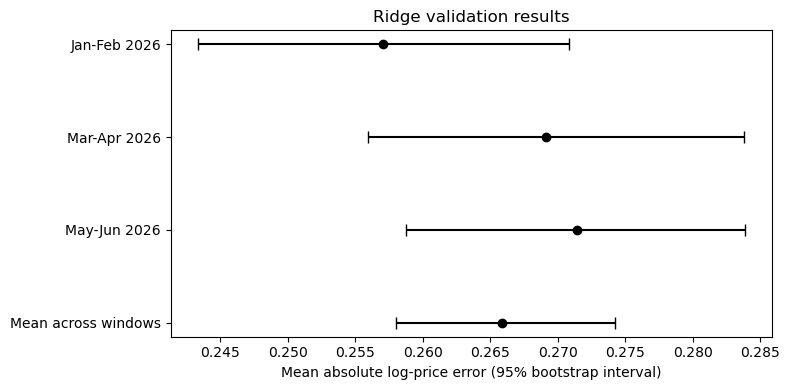

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
positions = np.arange(len(summary))
lower_error = summary["MAE"] - summary["Lower 95%"]
upper_error = summary["Upper 95%"] - summary["MAE"]
ax.errorbar(summary["MAE"], positions, xerr=[lower_error, upper_error],
            fmt="o", color="black", capsize=4)
ax.set_yticks(positions, summary.index)
ax.invert_yaxis()
ax.set_xlabel("Mean absolute log-price error (95% bootstrap interval)")
ax.set_title("Ridge validation results")
fig.tight_layout()
fig.savefig(figures / "baseline.png", dpi=150)
plt.show()

## Paired bootstrap dry run on May–June validation

In [9]:
# Fixed configurations for a diagnostic comparison, not tuned boosting results.
train = development[development["SALE DATE"] < "2026-05-01"]
validation = development[(development["SALE DATE"] >= "2026-05-01") &
                         (development["SALE DATE"] < "2026-07-01")]
x_train, x_validation = prepare_features(train, validation)
y_train = np.log(train["SALE PRICE"])
y_validation = np.log(validation["SALE PRICE"]).to_numpy()

ridge = Ridge(alpha=1.0, solver="lsqr", tol=1e-6)
ridge.fit(x_train, y_train)
boosting = XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.03,
                        reg_lambda=1, objective="reg:squarederror",
                        tree_method="hist", n_jobs=2, random_state=seed)
boosting.fit(x_train, y_train)

comparison = validation[["BOROUGH", "BLOCK"]].copy()
comparison["BLOCK"] = comparison["BLOCK"].astype(int)
comparison["ridge_error"] = np.abs(y_validation - ridge.predict(x_validation))
comparison["boosting_error"] = np.abs(y_validation - boosting.predict(x_validation))
comparison["rows"] = 1
blocks = comparison.groupby(["BOROUGH", "BLOCK"])[["ridge_error", "boosting_error", "rows"]].sum()

rng = np.random.default_rng(seed)
reductions = []
for repeat in range(n_bootstrap):
    totals = np.zeros(3)
    for borough in blocks.index.get_level_values("BOROUGH").unique():
        values = blocks.loc[borough].to_numpy()
        sampled_blocks = rng.integers(0, len(values), size=len(values))
        totals += values[sampled_blocks].sum(axis=0)
    reductions.append(100 * (totals[0] - totals[1]) / totals[0])

ridge_mae = comparison["ridge_error"].mean()
boosting_mae = comparison["boosting_error"].mean()
print("Fixed ridge log MAE:", ridge_mae)
print("Fixed boosting log MAE:", boosting_mae)
print("Reduction (%):", 100 * (ridge_mae - boosting_mae) / ridge_mae)
print("95% bootstrap interval:", np.quantile(reductions, [0.025, 0.975]))

Fixed ridge log MAE: 0.272212122937934
Fixed boosting log MAE: 0.3075028486854435
Reduction (%): -12.964421042907029
95% bootstrap interval: [-15.12698558 -10.70259135]
